# 03 · Результаты

Читает `results/runs.csv` и `results/predictions/` из ноутбука 02 и отвечает на три вопроса
работы: помогает ли sheaf-структура (H1), помогают ли новости (H2), зарабатывает ли стратегия (H3).
Таблицы сохраняются в `results/*.md`, графики в `figures/`.

Две методические оговорки. Тестовые окна соседних фолдов пересекаются на три месяца, поэтому
тесты на дневных рядах считаются на двух непересекающихся парах фолдов: A = фолды 0 + 2
(2024-10 … 2025-09) и B = фолды 1 + 3 (2025-01 … 2025-12). Сиды не усредняются в ансамбль:
статистики считаются отдельно для каждого сида, а в таблицах приводится медиана.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm, ttest_rel

RESULTS, FIG = Path('results'), Path('figures')
runs = pd.read_csv(RESULTS / 'runs.csv')
pred = pd.concat([pd.read_csv(f, parse_dates=['TRADEDATE']) for f in sorted((RESULTS / 'predictions').glob('*.csv.gz'))],
                 ignore_index=True)
pred['pred'] = pred[['p_down', 'p_flat', 'p_up']].values.argmax(1)
pred['score'] = pred['p_up'] - pred['p_down']              # скор для ранжирования в бэктесте
MODELS = ['NSD', 'GCN', 'GAT', 'MLP', 'LSTM', 'Majority']
TRAINED = MODELS[:5]
PAIRS = {'A (фолды 0+2)': (0, 2), 'B (фолды 1+3)': (1, 3)}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(runs)} прогонов, {len(pred):,} предсказаний')

250 прогонов, 1,389,985 предсказаний


## Сравнение моделей

Медиана по сидам внутри фолда, затем среднее и стандартное отклонение по четырём фолдам.
IC считается как средний по дням ранговый коэффициент корреляции между скором `P(UP) − P(DOWN)`
и фактической доходностью следующего дня: это то, что напрямую использует бэктест.

In [2]:
keys = ['tag', 'grid', 'fold', 'seed']
g = pred.groupby(keys + ['TRADEDATE'])
pred['rs'], pred['rr'] = g['score'].rank(), g['FUTURE_RETURN'].rank()
ic_day = pred.groupby(keys + ['TRADEDATE'])[['rs', 'rr']].corr().iloc[0::2, 1].droplevel(-1)
runs = runs.merge(ic_day.groupby(keys).mean().rename('ic').reset_index(), on=keys, how='left')


def summary(df):
    per_fold = df.groupby(['tag', 'fold'])[['mcc', 'ic', 'f1', 'f1_down', 'acc']].median()
    agg = per_fold.groupby('tag').agg(['mean', 'std'])
    out = pd.DataFrame({'MCC': agg[('mcc', 'mean')], '± sd по фолдам': agg[('mcc', 'std')],
                        'MCC min…max': per_fold.groupby('tag')['mcc'].agg(lambda s: f'{s.min():+.3f} … {s.max():+.3f}'),
                        'IC': agg[('ic', 'mean')], 'Macro-F1': agg[('f1', 'mean')],
                        'F1-DOWN': agg[('f1_down', 'mean')], 'Accuracy': agg[('acc', 'mean')]})
    return out.sort_values('MCC', ascending=False)


main = summary(runs.query("grid == '4x18' and tag in @MODELS"))
(RESULTS / 'models.md').write_text(main.round(4).to_markdown(), encoding='utf-8')
main.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
LSTM,0.0734,0.0133,+0.059 … +0.091,0.0224,0.3677,0.3659,0.3839
GAT,0.0085,0.0177,-0.013 … +0.026,0.0041,0.3174,0.3670,0.3357
GCN,0.0084,0.0266,-0.027 … +0.031,0.0036,0.3247,0.3450,0.3338
NSD,0.0077,0.0243,-0.018 … +0.037,-0.0046,0.3242,0.3724,0.3370
MLP,0.0071,0.0185,-0.012 … +0.028,0.0117,0.3243,0.3916,0.3380
Majority,0.0000,0.0000,+0.000 … +0.000,NaN,0.1616,0.0000,0.3201


Все модели с признаками узла (NSD, GCN, GAT и MLP) дают MCC около +0,008 при разбросе по фолдам
0,02: их нельзя отличить ни от нуля, ни друг от друга. Единственная модель со стабильно положительным
MCC: LSTM на 20-дневном окне цен, без новостей и без графа: +0,073, минимум по фолдам +0,059.
IC у LSTM +0,022, у остальных в пределах ±0,01.

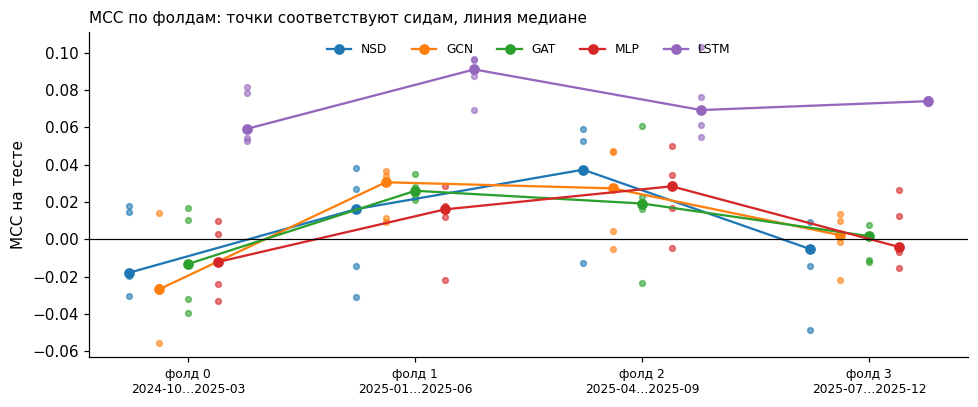

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sub = runs.query("grid == '4x18' and tag in @TRAINED")
for i, tag in enumerate(TRAINED):
    r = sub[sub.tag == tag]
    ax.scatter(r['fold'] + (i - 2) * 0.13, r['mcc'], s=14, alpha=0.6, color=f'C{i}')
    med = r.groupby('fold')['mcc'].median()
    ax.plot(med.index + (i - 2) * 0.13, med.values, 'o-', color=f'C{i}', ms=6, label=tag)
ax.axhline(0, c='k', lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels([f'фолд {i}\n{te[0]}…{te[-1]}' for i, te in
    enumerate([('2024-10', '2025-03'), ('2025-01', '2025-06'), ('2025-04', '2025-09'), ('2025-07', '2025-12')])], fontsize=8)
ax.set_ylabel('MCC на тесте'); ax.legend(ncol=5, fontsize=8, frameon=False, loc='upper center')
ax.set_title('MCC по фолдам: точки соответствуют сидам, линия медиане', fontsize=10, loc='left')
fig.tight_layout(); fig.savefig(FIG / 'mcc_by_fold.png'); plt.show()

## Абляция NSD

Та же процедура; базовая конфигурация `NSD` (hidden 64, d = 4, L = 2, граф corr-MST, новости включены).

In [4]:
abl = summary(runs.query("grid == '4x18' and tag.str.startswith('NSD')", engine='python'))
(RESULTS / 'ablation.md').write_text(abl.round(4).to_markdown(), encoding='utf-8')
abl.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
NSD news_off,0.0266,0.0171,+0.012 … +0.050,0.0077,0.3423,0.3553,0.3546
NSD L=3,0.0086,0.0311,-0.021 … +0.052,-0.0087,0.3206,0.3620,0.3377
NSD,0.0077,0.0243,-0.018 … +0.037,-0.0046,0.3242,0.3724,0.3370
NSD L=1,0.0074,0.0338,-0.032 … +0.039,-0.0071,0.3306,0.3762,0.3389
NSD d=6,0.0051,0.0046,+0.001 … +0.012,0.0003,0.3231,0.3784,0.3375
NSD d=2,0.0025,0.0246,-0.027 … +0.025,-0.0028,0.3212,0.3794,0.3369
NSD sector,-0.0102,0.0136,-0.024 … +0.002,-0.0086,0.3124,0.3926,0.3295


Отключение новостей не ухудшает, а улучшает NSD: +0,027 против +0,008, и все четыре фолда
положительны. На этих данных 768 текстовых признаков служат источником шума, а не сигнала. Размерность
стебля и число слоёв ничего не меняют (всё в пределах ±0,01 при разбросе 0,02–0,03), статический
секторный граф чуть хуже корреляционного.

## Парные сравнения

Два теста. Парный t-тест по четырём фолдам на медианах по сидам грубый, но учитывает,
что сравниваемые модели видят одни и те же окна. Тест Диболда-Мариано на дневном ряде
средней ошибки направления с HAC-дисперсией Ньюи-Уэста считается на непересекающихся
парах фолдов отдельно по каждому сиду; вердикт «значимо» ставится только при согласии
всех пяти сидов по знаку и уровню.

In [5]:
def dm_test(la, lb):
    d = np.asarray(la) - np.asarray(lb); n = len(d); h = int(1.5 * n ** (1 / 3)); d0 = d - d.mean()
    lrv = d0 @ d0 / n + 2 * sum((1 - j / (h + 1)) * (d0[j:] @ d0[:-j]) / n for j in range(1, h + 1))
    stat = d.mean() / np.sqrt(max(lrv, 1e-12) / n)
    return stat, 2 * (1 - norm.cdf(abs(stat)))


def verdict(stats, ps):
    s = np.sign(stats)
    if len(set(s[s != 0])) > 1: return 'знак разный'
    if (ps < .05).all(): return 'значимо'
    return 'не все сиды' if (ps < .05).any() else 'не значимо'


def daily_loss(df):
    return (df['pred'] != df['y']).groupby(df['TRADEDATE']).mean()


COMPARE = [('NSD', 'GCN'), ('NSD', 'GAT'), ('NSD', 'MLP'), ('NSD', 'LSTM'), ('NSD news_off', 'NSD'), ('NSD sector', 'NSD')]
rows = []
for a, b in COMPARE:
    ma = runs.query("grid == '4x18' and tag == @a").groupby('fold')['mcc'].median()
    mb = runs.query("grid == '4x18' and tag == @b").groupby('fold')['mcc'].median()
    t, p = ttest_rel(ma, mb)
    row = {'сравнение': f'{a} − {b}', 'Δ MCC': (ma - mb).mean(), 'фолдов Δ>0': int((ma > mb).sum()), 't (n=4)': t, 'p': p}
    for name, folds in PAIRS.items():
        st = []
        for s in range(5):
            pa = pred.query("grid == '4x18' and tag == @a and fold in @folds and seed == @s")
            pb = pred.query("grid == '4x18' and tag == @b and fold in @folds and seed == @s")
            la, lb = daily_loss(pa).align(daily_loss(pb), join='inner')
            st.append(dm_test(la, lb))                      # DM < 0: у первой модели ошибка меньше
        st = np.array(st)
        row[f'DM {name}'] = f'{np.median(st[:, 0]):+.2f} ({verdict(st[:, 0], st[:, 1])})'
    rows.append(row)
tests = pd.DataFrame(rows).set_index('сравнение')
(RESULTS / 'tests.md').write_text(tests.round(4).to_markdown(), encoding='utf-8')
tests.round(4)

,Δ MCC,фолдов Δ>0,t (n=4),p,DM A (фолды 0+2),DM B (фолды 1+3)
сравнение,,,,,,
NSD − GCN,-0.0007,2,-0.1182,0.9133,-0.64 (знак разный),+0.67 (знак разный)
NSD − GAT,-0.0008,1,-0.1271,0.9069,-0.99 (знак разный),+0.38 (знак разный)
NSD − MLP,0.0006,2,0.1805,0.8683,-0.27 (знак разный),+0.31 (знак разный)
NSD − LSTM,-0.0658,0,-5.8157,0.0101,+2.25 (не все сиды),+3.62 (значимо)
NSD news_off − NSD,0.0189,3,1.0283,0.3795,-1.11 (знак разный),-0.95 (не все сиды)
NSD sector − NSD,-0.0178,0,-2.9071,0.0621,+1.65 (не все сиды),+0.89 (знак разный)


NSD статистически неотличим от GCN, GAT и MLP: p ≈ 0,9 по фолдам, статистика DM меняет знак от сида
к сиду. Отличие от LSTM значимо (p = 0,010 по фолдам; DM на паре B согласован по всем сидам).
Прирост от отключения новостей формально не значим (p = 0,38, n = 4), но его знак противоположен
гипотезе H2.

## Направленная предсказуемость: тест Пезарана-Тиммерманна

Бинаризация «класс против остальных» для UP и для DOWN. Статистика положительна, когда
предсказанный и реализованный знак согласованы чаще, чем при независимости.

In [6]:
def pt_test(y, p, cls):
    a, b = (y == cls).astype(float), (p == cls).astype(float); n = len(a)
    py, pz, ph = a.mean(), b.mean(), (a == b).mean()
    ps = py * pz + (1 - py) * (1 - pz)
    v = ps * (1 - ps) / n - ((2 * py - 1) ** 2 * pz * (1 - pz) / n + (2 * pz - 1) ** 2 * py * (1 - py) / n
                              + 4 * py * pz * (1 - py) * (1 - pz) / n ** 2)
    if v <= 0: return np.nan, np.nan
    st = (ph - ps) / np.sqrt(v)
    return st, 2 * (1 - norm.cdf(abs(st)))


rows = []
for tag in TRAINED + ['NSD news_off']:
    for name, folds in PAIRS.items():
        row = {'модель': tag, 'пара': name}
        for cls, cname in ((2, 'UP'), (0, 'DOWN')):
            st = np.array([pt_test(*pred.query("grid == '4x18' and tag == @tag and fold in @folds and seed == @s")[['y', 'pred']].values.T, cls)
                           for s in range(5)])
            row[f'PT {cname}'] = f'{np.median(st[:, 0]):+.2f} ({verdict(st[:, 0], st[:, 1])})'
        rows.append(row)
pt = pd.DataFrame(rows).set_index(['модель', 'пара'])
(RESULTS / 'pt_test.md').write_text(pt.to_markdown(), encoding='utf-8')
pt

PT UP              PT DOWN
модель       пара                                                   
NSD          A (фолды 0+2)  +0.91 (не все сиды)  -0.03 (знак разный)
             B (фолды 1+3)  +0.94 (знак разный)  -0.99 (знак разный)
GCN          A (фолды 0+2)  +0.01 (знак разный)  -2.02 (знак разный)
             B (фолды 1+3)  +1.33 (знак разный)  +1.08 (знак разный)
GAT          A (фолды 0+2)  +1.67 (знак разный)  -2.01 (знак разный)
             B (фолды 1+3)  +0.55 (знак разный)  +0.84 (не все сиды)
MLP          A (фолды 0+2)  +0.40 (знак разный)  -1.09 (знак разный)
             B (фолды 1+3)  +1.73 (знак разный)  +1.02 (знак разный)
LSTM         A (фолды 0+2)      +5.45 (значимо)      +3.36 (значимо)
             B (фолды 1+3)      +5.44 (значимо)      +7.89 (значимо)
NSD news_off A (фолды 0+2)  -0.16 (знак разный)  +1.75 (не все сиды)
             B (фолды 1+3)  -1.95 (не все сиды)  +0.26 (знак разный)

Воспроизводимый направленный сигнал есть только у LSTM: по обоим классам, на обеих парах фолдов,
при всех пяти сидах. У NSD и остальных моделей знак статистики меняется от сида к сиду, это шум.

## Бэктест

Стратегия: каждый день long equal-weight из десяти бумаг с наибольшим
`P(UP) − P(DOWN)`, дневная ребалансировка, без издержек. Бенчмарк: равновзвешенный портфель
всех тикеров вселенной (он считается из тех же данных и покрывает весь период; IMOEX в кэше
есть только с апреля 2025). Оборот: доля портфеля, заменяемая за день; по нему считается
доходность за вычетом комиссии 5 и 10 б.п. round-trip.

In [7]:
def topk(df, k=10):
    d = df.sort_values(['TRADEDATE', 'score'], ascending=[True, False]).groupby('TRADEDATE').head(k)
    ret = d.groupby('TRADEDATE')['FUTURE_RETURN'].mean()
    sets = d.groupby('TRADEDATE')['SECID'].apply(set)
    turn = pd.Series([1 - len(a & b) / k for a, b in zip(sets, sets.shift(1).fillna(sets))], index=sets.index)
    return ret, turn


def perf(r, turn=None):
    eq = (1 + r).cumprod()
    out = {'накопл.': eq.iloc[-1] - 1, 'Sharpe': r.mean() / r.std() * np.sqrt(252), 'макс. просадка': (eq / eq.cummax() - 1).min()}
    if turn is not None:
        out['оборот/день'] = turn.mean()
        for bp in (5, 10):
            out[f'накопл. при {bp} б.п.'] = (1 + r - turn * bp / 1e4).prod() - 1
    return out


rows, curves = [], {}
for name, folds in PAIRS.items():
    for tag in TRAINED + ['NSD news_off']:
        per_seed = []
        for s in range(5):
            r, turn = topk(pred.query("grid == '4x18' and tag == @tag and fold in @folds and seed == @s"))
            per_seed.append(perf(r, turn)); curves[(name, tag, s)] = (1 + r).cumprod()
        rows.append({'пара': name, 'стратегия': f'{tag} top-10', **pd.DataFrame(per_seed).median().to_dict()})
    ew = pred.query("grid == '4x18' and tag == 'NSD' and fold in @folds and seed == 0").groupby('TRADEDATE')['FUTURE_RETURN'].mean()
    rows.append({'пара': name, 'стратегия': 'равновзвешенный портфель', **perf(ew)}); curves[(name, 'EW', 0)] = (1 + ew).cumprod()
bt = pd.DataFrame(rows).set_index(['пара', 'стратегия'])
(RESULTS / 'backtest.md').write_text(bt.round(4).to_markdown(), encoding='utf-8')
bt.round(4)

накопл.  Sharpe  макс. просадка  \
пара          стратегия                                                   
A (фолды 0+2) NSD top-10                -0.0509 -0.0683         -0.2052   
              GCN top-10                 0.0019  0.1352         -0.2019   
              GAT top-10                -0.0133  0.0906         -0.1954   
              MLP top-10                 0.0380  0.2699         -0.2035   
              LSTM top-10               -0.1090 -0.2986         -0.2142   
              NSD news_off top-10        0.0169  0.1914         -0.2045   
              равновзвешенный портфель  -0.0589 -0.1135         -0.1949   
B (фолды 1+3) NSD top-10                -0.0924 -0.2627         -0.2759   
              GCN top-10                 0.0369  0.2687         -0.2187   
              GAT top-10                 0.0657  0.3744         -0.2097   
              MLP top-10                 0.0423  0.2883         -0.2073   
              LSTM top-10               -0.0289  0.0123         -0.2432   
              NSD news_off top-10        0.0357  0.2652         -0.2262   
              равновзвешенный портфель  -0.0214  0.0256         -0.2508   

                                        оборот/день  накопл. при 5 б.п.  \
пара          стратегия                                                   
A (фолды 0+2) NSD top-10                     0.7443             -0.1368   
              GCN top-10                     0.7220             -0.0894   
              GAT top-10                     0.7349             -0.1035   
              MLP top-10                     0.7616             -0.0580   
              LSTM top-10                    0.5945             -0.1753   
              NSD news_off top-10            0.7290             -0.0733   
              равновзвешенный портфель          NaN                 NaN   
B (фолды 1+3) NSD top-10                     0.7514             -0.1747   
              GCN top-10                     0.7561             -0.0541   
              GAT top-10                     0.7593             -0.0322   
              MLP top-10                     0.7344             -0.0469   
              LSTM top-10                    0.4996             -0.0942   
              NSD news_off top-10            0.7071             -0.0572   
              равновзвешенный портфель          NaN                 NaN   

                                        накопл. при 10 б.п.  
пара          стратегия                                      
A (фолды 0+2) NSD top-10                            -0.2151  
              GCN top-10                            -0.1725  
              GAT top-10                            -0.1854  
              MLP top-10                            -0.1452  
              LSTM top-10                           -0.2367  
              NSD news_off top-10                   -0.1556  
              равновзвешенный портфель                  NaN  
B (фолды 1+3) NSD top-10                            -0.2495  
              GCN top-10                            -0.1372  
              GAT top-10                            -0.1211  
              MLP top-10                            -0.1285  
              LSTM top-10                           -0.1550  
              NSD news_off top-10                   -0.1421  
              равновзвешенный портфель                  NaN

Ни одна стратегия не обыгрывает равновзвешенный портфель на обеих парах, NSD проигрывает ему на обеих.
Лучший MCC у LSTM оборачивается худшей доходностью: классификационное качество и прибыль портфеля
не связаны. Оборот 70–75 % портфеля в день; при 5 б.п. round-trip накопленная доходность
отрицательна у всех конфигураций.

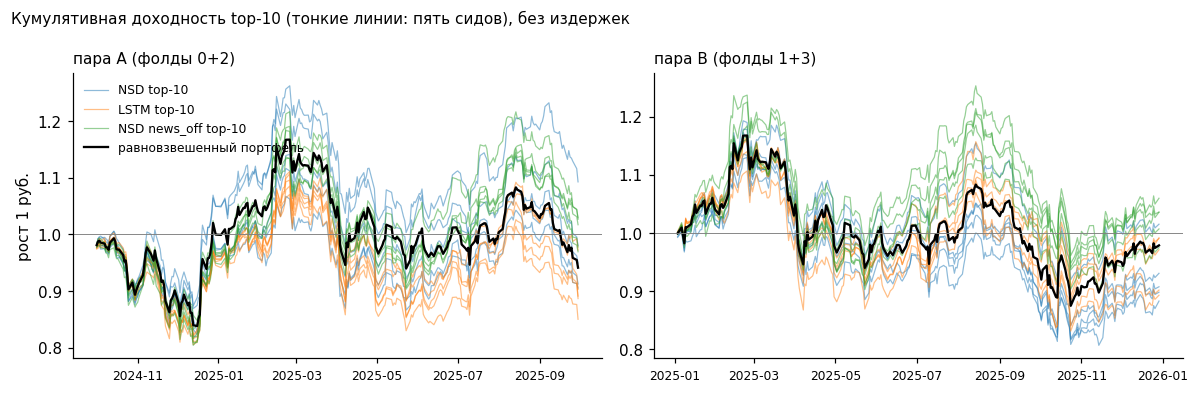

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, name in zip(axes, PAIRS):
    for i, tag in enumerate(['NSD', 'LSTM', 'NSD news_off']):
        for s in range(5):
            ax.plot(curves[(name, tag, s)], color=f'C{i}', lw=0.8, alpha=0.5, label=f'{tag} top-10' if s == 0 else None)
    ax.plot(curves[(name, 'EW', 0)], color='k', lw=1.5, label='равновзвешенный портфель')
    ax.axhline(1, c='grey', lw=0.6); ax.set_title(f'пара {name}', fontsize=10, loc='left'); ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('рост 1 руб.'); axes[0].legend(fontsize=8, frameon=False)
fig.suptitle('Кумулятивная доходность top-10 (тонкие линии: пять сидов), без издержек', fontsize=10, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(FIG / 'backtest.png'); plt.show()

## Чувствительность к сетке валидации

Та же модель NSD и тот же код на контрольной сетке 24/6/6 (два длинных фолда, у второго
тест три месяца) и на основной 18/6/6 (четыре фолда по шесть месяцев); по фолдам
приводятся медиана и разброс по пяти сидам.

In [9]:
grid_cmp = (runs.query("tag == 'NSD'").groupby(['grid', 'fold'])['mcc']
                .agg(медиана='median', min='min', max='max').round(4))
grid_cmp.loc[('4x18', 'среднее'), :] = [grid_cmp.loc['4x18', 'медиана'].mean(), np.nan, np.nan]
grid_cmp.loc[('2x24', 'среднее'), :] = [grid_cmp.loc['2x24', 'медиана'].mean(), np.nan, np.nan]
(RESULTS / 'grid_comparison.md').write_text(grid_cmp.round(4).to_markdown(), encoding='utf-8')
grid_cmp.round(4)

медиана     min     max
grid fold                            
2x24 0         0.0242  0.0156  0.0628
     1         0.0198  0.0050  0.0400
4x18 0        -0.0178 -0.0303  0.0182
     1         0.0162 -0.0310  0.0383
     2         0.0374 -0.0124  0.0591
     3        -0.0051 -0.0487  0.0092
     среднее   0.0077     NaN     NaN
2x24 среднее   0.0220     NaN     NaN

На двух длинных фолдах NSD даёт +0,022 при разбросе по сидам от +0,005 до +0,063, на четырёх
+0,008. Разброс по сидам внутри одного фолда втрое больше разницы между графовыми моделями:
оценка по одному сиду и двум фолдам могла бы показать любое значение из этого диапазона.
Отсюда протокол: медиана по пяти сидам, среднее по четырём фолдам, парные тесты по фолдам.

## Итог

* **H1** (sheaf-структура даёт прирост над GCN и GAT) не подтверждается: разница в пределах 0,001 MCC.
* **H2** (новости улучшают прогноз) не подтверждается; знак эффекта обратный.
* **H3** (стратегия обыгрывает пассивный портфель) не подтверждается.

Единственный воспроизводимый результат: предсказуемость знака дневной доходности по 20-дневному
окну цен (LSTM), и она не превращается в прибыль портфеля: издержки при дневной ребалансировке
съедают всё.